<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# <center> Проект: Анализ резюме из HeadHunter
   

In [1]:
#%pip install pandas==3.0.5 numpy==2.5.2 matplotlib==3.11.2 seaborn==0.13.2 plotly==7.1.0
#%pip install -r requirements.txt

In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import re
from importlib.metadata import version

print("python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", version("matplotlib"))
print("seaborn:", sns.__version__)
print("plotly:", version("plotly"))


python: 3.14.7
pandas: 3.0.5
numpy: 2.5.2
matplotlib: 3.11.2
seaborn: 0.13.2
plotly: 7.1.0


# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [3]:
hh_data = pd.read_csv('dst-3.0_16_1_hh_database.csv', sep=';', encoding='utf-8')

2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [4]:
display(hh_data.head())
display(hh_data.tail())

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
0,"Мужчина , 39 лет , родился 27 ноября 1979",29000 руб.,Системный администратор,"Советск (Калининградская область) , не готов к...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, ва...",Опыт работы 16 лет 10 месяцев Август 2010 — п...,"МАОУ ""СОШ № 1 г.Немана""",Системный администратор,Неоконченное высшее образование 2000 Балтийск...,16.04.2019 15:59,Имеется собственный автомобиль
1,"Мужчина , 60 лет , родился 20 марта 1959",40000 руб.,Технический писатель,"Королев , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, уд...",Опыт работы 19 лет 5 месяцев Январь 2000 — по...,Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель",Высшее образование 1981 Военно-космическая ак...,12.04.2019 08:42,Не указано
2,"Женщина , 36 лет , родилась 12 августа 1982",20000 руб.,Оператор,"Тверь , не готова к переезду , не готова к ком...",полная занятость,полный день,Опыт работы 10 лет 3 месяца Октябрь 2004 — Де...,ПАО Сбербанк,Кассир-операционист,Среднее специальное образование 2002 Профессио...,16.04.2019 08:35,Не указано
3,"Мужчина , 38 лет , родился 25 июня 1980",100000 руб.,Веб-разработчик (HTML / CSS / JS / PHP / базы ...,"Саратов , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, удаленная работа",Опыт работы 18 лет 9 месяцев Август 2017 — Ап...,OpenSoft,Инженер-программист,Высшее образование 2002 Саратовский государст...,08.04.2019 14:23,Не указано
4,"Женщина , 26 лет , родилась 3 марта 1993",140000 руб.,Региональный менеджер по продажам,"Москва , не готова к переезду , готова к коман...",полная занятость,полный день,Опыт работы 5 лет 7 месяцев Региональный мене...,Мармелад,Менеджер по продажам,Высшее образование 2015 Кгу Психологии и педаг...,22.04.2019 10:32,Не указано


,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
44739,"Мужчина , 30 лет , родился 17 января 1989",50000 руб.,"Финансист, аналитик, экономист, бухгалтер, мен...","Тверь , готов к переезду (Москва, Химки) , гот...",полная занятость,"полный день, удаленная работа","Опыт работы 7 лет 7 месяцев Финансист, аналит...","ООО ""IAS"" (независимый участник объединения Ru...",Руководитель субгруппы,Высшее образование 2015 Московский гуманитарн...,22.04.2019 12:32,Не указано
44740,"Мужчина , 27 лет , родился 5 марта 1992",39000 руб.,"Системный администратор, IT-специалист","Липецк , готов к переезду , готов к командировкам","проектная работа, частичная занятость, полная ...","удаленная работа, гибкий график, полный день, ...","Опыт работы 7 лет Системный администратор, IT...",ИП Пестрецов,Предприниматель,Высшее образование (Бакалавр) 2016 Воронежски...,22.04.2019 13:11,Не указано
44741,"Женщина , 48 лет , родилась 26 декабря 1970",40000 руб.,"Аналитик данных, Математик","Челябинск , готова к переезду , готова к редки...",полная занятость,"полный день, удаленная работа",Опыт работы 21 год 5 месяцев Январь 1998 — по...,"ОАО «ЧМК», Исследовательско-Технологический Це...",Начальник группы аналитики,Высшее образование 2000 Южно-Уральский госуда...,09.04.2019 05:07,Не указано
44742,"Мужчина , 24 года , родился 6 октября 1994",20000 руб.,Контент-менеджер,"Тамбов , не готов к переезду , не готов к кома...","частичная занятость, полная занятость",удаленная работа,Опыт работы 3 года 10 месяцев Контент-менедже...,IQ-Maxima,Менеджер проектов,Высшее образование 2015 Тамбовский государств...,26.04.2019 14:25,Имеется собственный автомобиль
44743,"Мужчина , 38 лет , родился 25 апреля 1980",120000 руб.,Руководитель проекта,"Москва , не готов к переезду , не готов к кома...",полная занятость,полный день,Опыт работы 15 лет 10 месяцев Руководитель пр...,ПАО ГК ТНС энерго,Руководитель отдела технической поддержки,Высшее образование 1997 Южно-Российский госуд...,05.07.2018 20:15,Не указано


3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

4. Обратите внимание на информацию о числе непустых значений.

In [5]:
hh_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   Пол, возраст                     44744 non-null  str  
 1   ЗП                               44744 non-null  str  
 2   Ищет работу на должность:        44744 non-null  str  
 3   Город, переезд, командировки     44744 non-null  str  
 4   Занятость                        44744 non-null  str  
 5   График                           44744 non-null  str  
 6   Опыт работы                      44576 non-null  str  
 7   Последнее/нынешнее место работы  44743 non-null  str  
 8   Последняя/нынешняя должность     44742 non-null  str  
 9   Образование и ВУЗ                44744 non-null  str  
 10  Обновление резюме                44744 non-null  str  
 11  Авто                             44744 non-null  str  
dtypes: str(12)
memory usage: 4.1 MB


5. Выведите основную статистическую информацию о столбцах.


In [6]:
hh_data.describe()

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
count,44744,44744,44744,44744,44744,44744,44576,44743,44742,44744,44744,44744
unique,16003,690,14929,10063,38,47,44413,30214,16927,40148,18838,2
top,"Мужчина , 32 года , родился 17 сентября 1986",50000 руб.,Системный администратор,"Москва , не готов к переезду , не готов к кома...",полная занятость,полный день,Опыт работы 10 лет 8 месяцев Апрель 2018 — по...,Индивидуальное предпринимательство / частная п...,Системный администратор,Высшее образование 2014 Московский технически...,07.05.2019 09:50,Не указано
freq,18,4064,3099,1261,30026,22727,3,935,2062,4,25,32268


# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [7]:
def extract_education(row):
    if pd.isna(row):
        return np.nan
    words = row.split()[:2]
    edu = ' '.join(words).lower()
    if 'неоконченное' in edu:
        return 'неоконченное высшее'
    elif 'высшее' in edu:
        return 'высшее'
    elif 'среднее специальное' in edu:
        return 'среднее специальное'
    elif 'среднее' in edu:
        return 'среднее'
    return np.nan


In [8]:
# 1. Применяем функцию и создаём новый столбец
hh_data['Образование'] = hh_data['Образование и ВУЗ'].apply(extract_education)

# 2. Проверяем список уникальных категорий (должно быть ровно 4, без nan)
print(hh_data['Образование'].unique())

# 3. Смотрим количество резюме в каждой категории (пригодится для контрольного вопроса)
print(hh_data['Образование'].value_counts(dropna=False))

<StringArray>
['неоконченное высшее', 'высшее', 'среднее специальное', 'среднее']
Length: 4, dtype: str
Образование
высшее                 33863
среднее специальное     5765
неоконченное высшее     4557
среднее                  559
Name: count, dtype: int64


In [9]:
hh_data = hh_data.drop('Образование и ВУЗ', axis=1)

2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '. 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [10]:
def get_gender(text):
    return text.split(' , ')[0][0].upper()

def get_age(text):
    age_str = text.split(' , ')[1]
    digits = ''.join(filter(str.isdigit, age_str))
    return int(digits)

hh_data['Пол'] = hh_data['Пол, возраст'].apply(get_gender)
hh_data['Возраст'] = hh_data['Пол, возраст'].apply(get_age)

print(hh_data[['Пол, возраст', 'Пол', 'Возраст']].head())

hh_data = hh_data.drop('Пол, возраст', axis=1)

                                   Пол, возраст Пол  Возраст
0    Мужчина ,  39 лет , родился 27 ноября 1979   М       39
1     Мужчина ,  60 лет , родился 20 марта 1959   М       60
2  Женщина ,  36 лет , родилась 12 августа 1982   Ж       36
3      Мужчина ,  38 лет , родился 25 июня 1980   М       38
4     Женщина ,  26 лет , родилась 3 марта 1993   Ж       26


3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [11]:
def get_experience(arg):
    # 1. Проверяем на обычные пропуски (NaN) и скрытые ('Не указано')
    if pd.isna(arg) or arg == 'Не указано':
        return np.nan
    
    words = arg.split()[:6]
    
    years = 0
    months = 0
    
    year_words = ['год', 'года', 'лет']
    month_words = ['месяц', 'месяца', 'месяцев']
    
    # Проходим по словам и забираем число перед единицей измерения
    for i, word in enumerate(words):
        if word in year_words:
            # Проверка, что индекс не равен 0, чтобы не взять последний элемент
            if i > 0:
                try:
                    years = int(words[i - 1])
                except ValueError:
                    pass  # Если перед словом "год" не число, просто пропускаем
                    
        if word in month_words:
            if i > 0:
                try:
                    months = int(words[i - 1])
                except ValueError:
                    pass
                    
    return years * 12 + months

# Применяем функцию и создаём новый столбец
hh_data['Опыт работы (месяц)'] = hh_data['Опыт работы'].apply(get_experience)

# Удаляем исходный столбец
hh_data = hh_data.drop('Опыт работы', axis=1)

# Проверяем медианный опыт работы (ответ на контрольный вопрос) и число пропусков
print("Медианный опыт работы (в месяцах):", hh_data['Опыт работы (месяц)'].median())
print("Количество пропусков:", hh_data['Опыт работы (месяц)'].isna().sum())

Медианный опыт работы (в месяцах): 100.0
Количество пропусков: 170


4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [12]:
def get_city(arg):
    million_cities = [
        'Новосибирск', 'Екатеринбург', 'Нижний Новгород', 'Казань', 
        'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 
        'Красноярск', 'Пермь', 'Воронеж', 'Волгоград'
    ]
    
    city = arg.split(',')[0].strip()
    
    if city == 'Москва' or city == 'Санкт-Петербург':
        return city
    elif city in million_cities:
        return 'город-миллионник'
    else:
        return 'другие'


def get_relocation(arg):
    # Проверяем формулировки отрицания
    if ('не готов к переезду' in arg) or ('не готова к переезду' in arg):
        return False
    # Если отрицания нет, но упоминается переезд ('готов к переезду', 'готова к переезду', 'хочу переехать')
    elif 'перее' in arg:
        return True
    return False


def get_business_trips(arg):
    # Сначала проверяем наличие слова 'командировк' (если его нет — информация потерялась -> False)
    if 'командировк' in arg:
        if ('не готов к командировкам' in arg) or ('не готова к командировкам' in arg):
            return False
        return True
    return False


# Создаём новые столбцы
hh_data['Город'] = hh_data['Город, переезд, командировки'].apply(get_city)
hh_data['Готовность к переезду'] = hh_data['Город, переезд, командировки'].apply(get_relocation)
hh_data['Готовность к командировкам'] = hh_data['Город, переезд, командировки'].apply(get_business_trips)

# Проверка результатов и статистика для контрольных вопросов
print("Категории городов:\n", hh_data['Город'].value_counts(normalize=True) * 100)
print("\nГотовы и к переезду, и к командировкам (%):", 
      round(hh_data[hh_data['Готовность к переезду'] & hh_data['Готовность к командировкам']].shape[0] / hh_data.shape[0] * 100))


Категории городов:
 Город
Москва              37.146880
другие              35.432684
город-миллионник    16.386555
Санкт-Петербург     11.033882
Name: proportion, dtype: float64

Готовы и к переезду, и к командировкам (%): 32


In [13]:
hh_data = hh_data.drop('Город, переезд, командировки', axis=1)

5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [14]:
employments = ['полная занятость', 'частичная занятость', 'проектная работа', 'волонтерство', 'стажировка']
schedules = ['полный день', 'сменный график', 'гибкий график', 'удаленная работа', 'вахтовый метод']


for emp in employments:
    hh_data[emp] = hh_data['Занятость'].apply(lambda x: emp in x.lower() if pd.notna(x) else False)

for sch in schedules:
    hh_data[sch] = hh_data['График'].apply(lambda x: sch in x.lower() if pd.notna(x) else False)

hh_data = hh_data.drop(['Занятость', 'График'], axis=1)

In [15]:
# 1. Сколько людей ищут проектную работу и волонтерство
ans_1 = hh_data[hh_data['проектная работа'] & hh_data['волонтерство']].shape[0]

# 2. Сколько людей хотят работать вахтовым методом и с гибким графиком
ans_2 = hh_data[hh_data['вахтовый метод'] & hh_data['гибкий график']].shape[0]

print(f'Первый ответ: {ans_1}')
print(f'Второй ответ: {ans_2}')

Первый ответ: 436
Второй ответ: 2311


6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования: 
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [16]:
currency = pd.read_csv('ExchangeRates.csv', sep=',')
hh_data['Обновление резюме'] = pd.to_datetime(hh_data['Обновление резюме'], format='%d.%m.%Y %H:%M').dt.date
currency['date'] = pd.to_datetime(currency['date'], format='%d/%m/%y').dt.date

currency_map = {
    'руб.': 'RUB',
    'бел.руб.': 'BYN',
    'KZT': 'KZT',
    'EUR': 'EUR',
    'USD': 'USD',
    'грн.': 'UAH',
    'сум': 'UZS',
    'KGS': 'KGS',
    'AZN': 'AZN'
}

hh_data['ЗП (сумма)'] = hh_data['ЗП'].apply(lambda x: float(x.split(' ')[0]))
hh_data['ЗП (валюта)'] = hh_data['ЗП'].apply(lambda x: x.split(' ')[1]).replace(currency_map)

hh_data = hh_data.merge(
    currency,
    left_on=['Обновление резюме', 'ЗП (валюта)'],
    right_on=['date', 'currency'],
    how='left'
)

hh_data['close'] = hh_data['close'].fillna(1)
hh_data['proportion'] = hh_data['proportion'].fillna(1)

hh_data['ЗП (руб)'] = hh_data['ЗП (сумма)'] * hh_data['close'] / hh_data['proportion']
cols_to_drop = ['ЗП', 'ЗП (сумма)', 'ЗП (валюта)', 'date', 'currency', 'per', 'time', 'close', 'vol', 'proportion']
hh_data = hh_data.drop(columns=[col for col in cols_to_drop if col in hh_data.columns])


In [17]:
median_salary = round(hh_data['ЗП (руб)'].median())
print(median_salary)

59019


In [18]:
hh_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Ищет работу на должность:        44744 non-null  str    
 1   Последнее/нынешнее место работы  44743 non-null  str    
 2   Последняя/нынешняя должность     44742 non-null  str    
 3   Обновление резюме                44744 non-null  object 
 4   Авто                             44744 non-null  str    
 5   Образование                      44744 non-null  str    
 6   Пол                              44744 non-null  str    
 7   Возраст                          44744 non-null  int64  
 8   Опыт работы (месяц)              44574 non-null  float64
 9   Город                            44744 non-null  str    
 10  Готовность к переезду            44744 non-null  bool   
 11  Готовность к командировкам       44744 non-null  bool   
 12  полная занятость             

# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

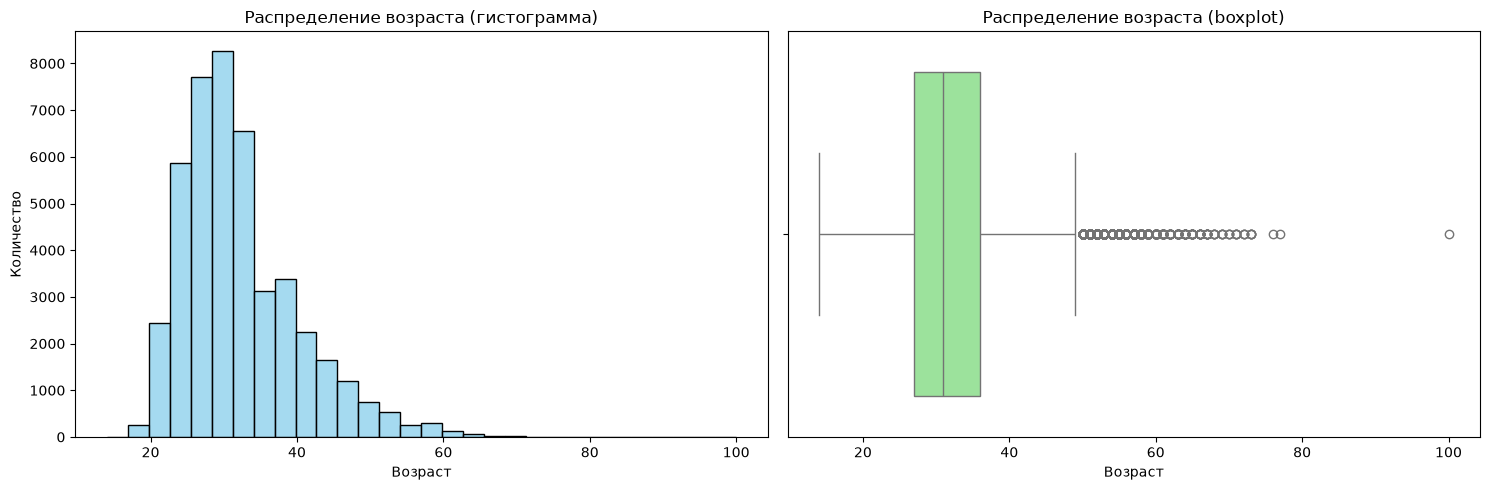

Мода возраста: 30
Минимальный возраст: 14
Максимальный возраст: 100
25-й перцентиль: 27.0
75-й перцентиль: 36.0


In [19]:
# Настраиваем размер фигуры (гистограмма и боксплот рядом)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Гистограмма
sns.histplot(data=hh_data, x='Возраст', bins=30, ax=axes[0], color='skyblue')
axes[0].set_title('Распределение возраста (гистограмма)')
axes[0].set_xlabel('Возраст')
axes[0].set_ylabel('Количество')

# Коробчатая диаграмма
sns.boxplot(data=hh_data, x='Возраст', ax=axes[1], color='lightgreen')
axes[1].set_title('Распределение возраста (boxplot)')

plt.tight_layout()
plt.show()

# Выводим статистику для выводов
print(f"Мода возраста: {hh_data['Возраст'].mode()[0]}")
print(f"Минимальный возраст: {hh_data['Возраст'].min()}")
print(f"Максимальный возраст: {hh_data['Возраст'].max()}")
print(f"25-й перцентиль: {hh_data['Возраст'].quantile(0.25)}")
print(f"75-й перцентиль: {hh_data['Возраст'].quantile(0.75)}")


• Мода: 30 лет.
• Предельные значения: от 14 до 100 лет.
• Основной интервал (межквартильный размах, 50% соискателей): примерно от 27 до 36 лет (основная масса активных соискателей — от 20 до 45 лет).
• Аномалии: соискатель с возрастом 100 лет (явный выброс), а также значения старше 70–75 лет и младше 16 лет требуют проверки на корректность.

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

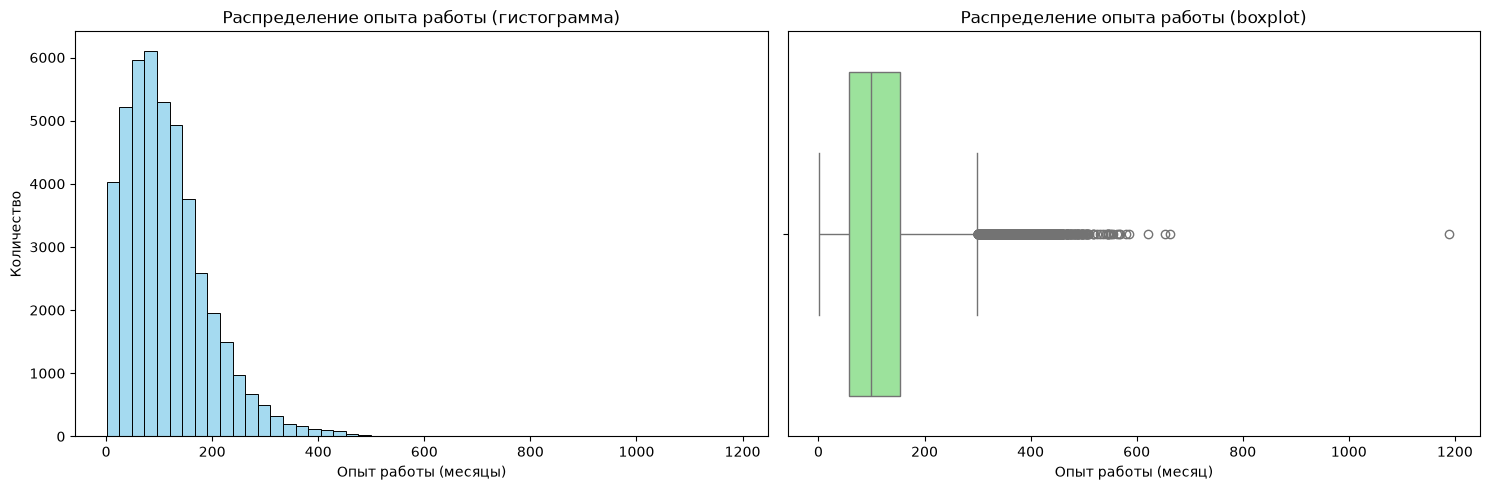

Мода опыта: 81.0
Минимум: 1.0
Максимум: 1188.0
25-й перцентиль: 57.0
75-й перцентиль: 154.0


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Гистограмма
sns.histplot(data=hh_data, x='Опыт работы (месяц)', bins=50, ax=axes[0], color='skyblue')
axes[0].set_title('Распределение опыта работы (гистограмма)')
axes[0].set_xlabel('Опыт работы (месяцы)')
axes[0].set_ylabel('Количество')

# Коробчатая диаграмма
sns.boxplot(data=hh_data, x='Опыт работы (месяц)', ax=axes[1], color='lightgreen')
axes[1].set_title('Распределение опыта работы (boxplot)')

plt.tight_layout()
plt.show()

# Статистика
print(f"Мода опыта: {hh_data['Опыт работы (месяц)'].mode()[0]}")
print(f"Минимум: {hh_data['Опыт работы (месяц)'].min()}")
print(f"Максимум: {hh_data['Опыт работы (месяц)'].max()}")
print(f"25-й перцентиль: {hh_data['Опыт работы (месяц)'].quantile(0.25)}")
print(f"75-й перцентиль: {hh_data['Опыт работы (месяц)'].quantile(0.75)}")

• Мода: 81 месяц (около 6.75 лет).
• Предельные значения: от 1 до 1188 месяцев.
• Основной интервал (50% соискателей): от 57 до 154 месяцев (примерно от 4.5 до 13 лет).
• Аномалии: значение 1188 месяцев (это 99 лет непрерывного стажа) — явная ошибка ввода или системный сбой; также аномальными можно считать значения свыше 600 месяцев (50 лет стажа) и случаи, когда опыт работы превышает возраст соискателя.

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


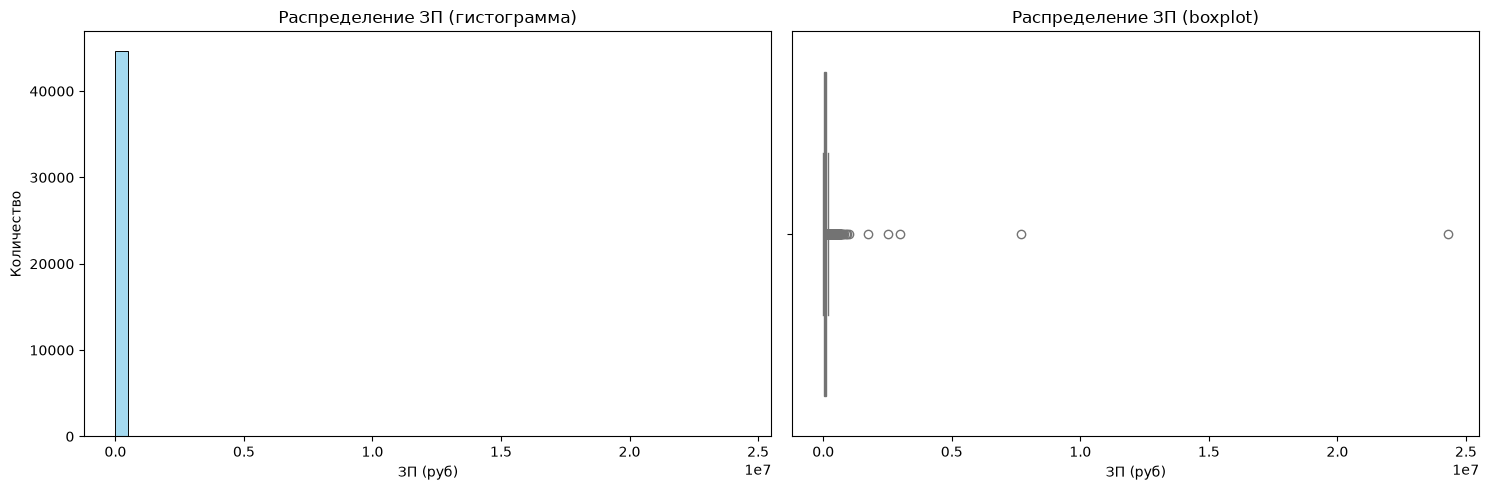

Минимум: 1.0
Максимум: 24304876.0
Медиана: 59019.0
25-й перцентиль: 37082.2
75-й перцентиль: 95000.0


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Гистограмма
sns.histplot(data=hh_data, x='ЗП (руб)', bins=50, ax=axes[0], color='skyblue')
axes[0].set_title('Распределение ЗП (гистограмма)')
axes[0].set_xlabel('ЗП (руб)')
axes[0].set_ylabel('Количество')

# Коробчатая диаграмма
sns.boxplot(data=hh_data, x='ЗП (руб)', ax=axes[1], color='lightgreen')
axes[1].set_title('Распределение ЗП (boxplot)')

plt.tight_layout()
plt.show()

# Статистика
print(f"Минимум: {hh_data['ЗП (руб)'].min()}")
print(f"Максимум: {hh_data['ЗП (руб)'].max()}")
print(f"Медиана: {hh_data['ЗП (руб)'].median()}")
print(f"25-й перцентиль: {hh_data['ЗП (руб)'].quantile(0.25)}")
print(f"75-й перцентиль: {hh_data['ЗП (руб)'].quantile(0.75)}")



• Медиана: 59 019 рублей.
• Предельные значения: от 1 рубля до ~24.3 млн рублей.
• Основной интервал (50% соискателей): от ~37 000 до 95 000 рублей (подавляющее большинство укладывается в диапазон до 200–300 тыс. рублей).
• Аномалии: экстремальные выбросы в обе стороны — желаемая зарплата более 1 млн рублей (вплоть до 24 млн руб., что сильно сжимает основной график влево), а также нереалистично низкие значения (меньше 10 000 руб., вплоть до 1 руб.).


4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

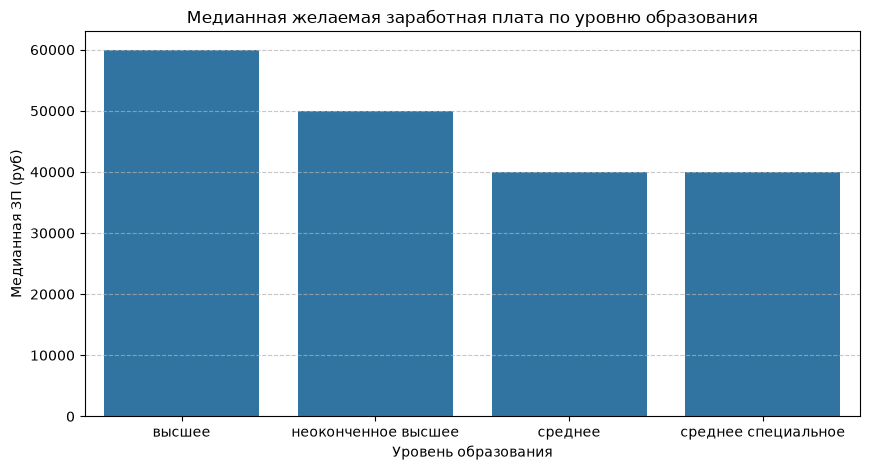

In [22]:
bar_data = hh_data[hh_data['ЗП (руб)'] < 1_000_000].groupby('Образование', as_index=False)['ЗП (руб)'].median()

fig = plt.figure(figsize=(10, 5))
sns.barplot(
    data=bar_data,
    x='Образование',
    y='ЗП (руб)'
)
plt.title('Медианная желаемая заработная плата по уровню образования')
plt.xlabel('Уровень образования')
plt.ylabel('Медианная ЗП (руб)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


Наибольший уровень медианной желаемой заработной платы наблюдается у соискателей с высшим образованием. Наименьший — у людей со средним образованием. Признак уровня образования важен при прогнозировании зарплаты, так как прослеживается четкая тенденция: чем выше образование, тем выше зарплатные ожидания (однако разница между "неоконченным высшим" и "средним специальным" может быть не столь значительной)

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

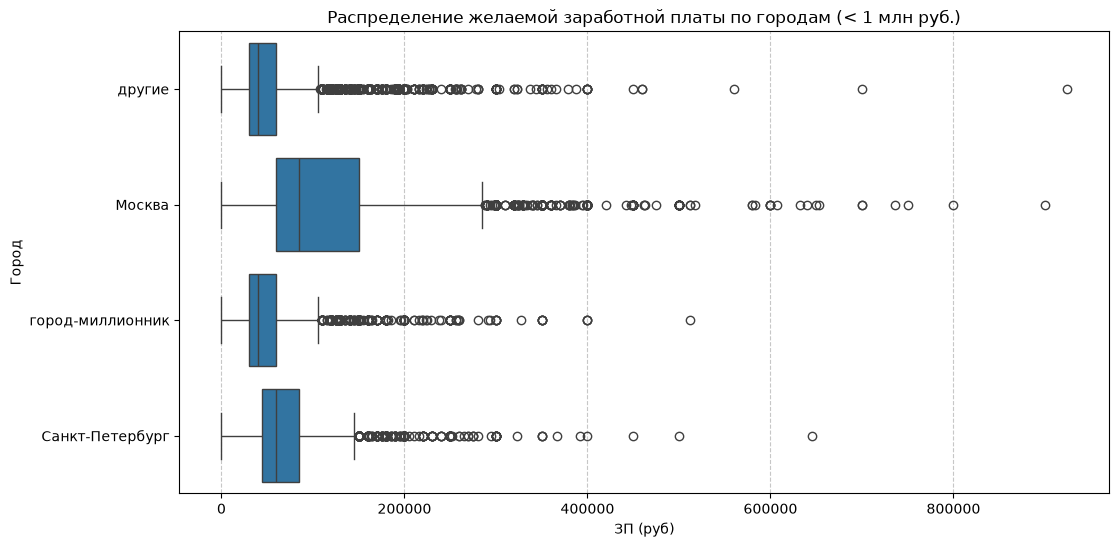

In [23]:
box_data = hh_data[hh_data['ЗП (руб)'] < 1_000_000]

fig = plt.figure(figsize=(12, 6))
sns.boxplot(
    data=box_data,
    x='ЗП (руб)',
    y='Город'
)
plt.title('Распределение желаемой заработной платы по городам (< 1 млн руб.)')
plt.xlabel('ЗП (руб)')
plt.ylabel('Город')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Самый высокий медианный уровень желаемой заработной платы ожидаемо в Москве, чуть ниже — в Санкт-Петербурге. В городах-миллионниках и "других" городах медиана ниже, однако размах (разброс) зарплат там достаточно большой. Признак города однозначно важен, так как уровень жизни и зарплат сильно дифференцирован по регионам

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

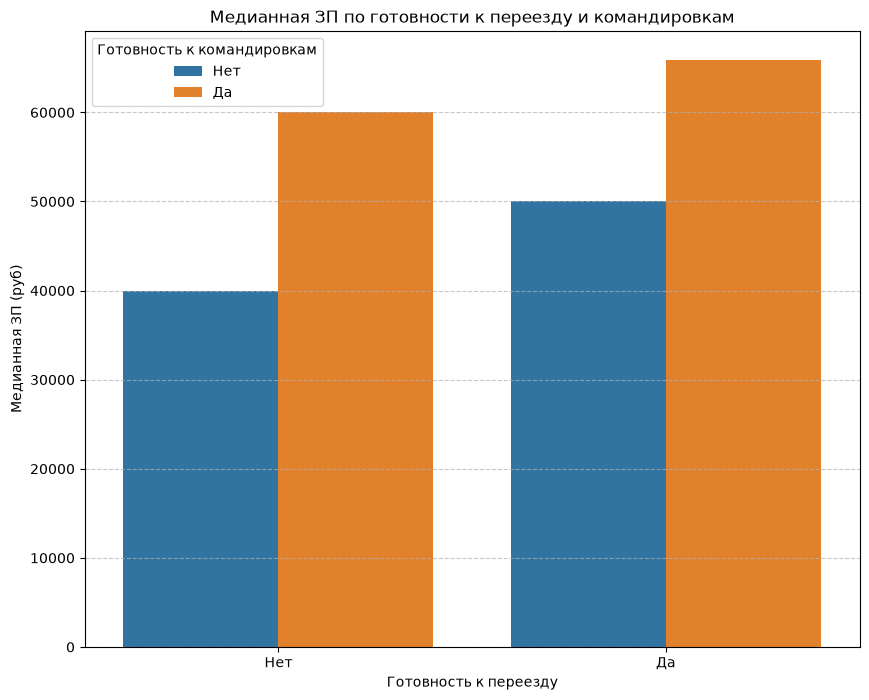

In [24]:
grouped_data = hh_data.groupby(
    ['Готовность к переезду', 'Готовность к командировкам'],
    as_index=False
)['ЗП (руб)'].median()

grouped_data['Готовность к переезду'] = grouped_data['Готовность к переезду'].map({True: 'Да', False: 'Нет'})
grouped_data['Готовность к командировкам'] = grouped_data['Готовность к командировкам'].map({True: 'Да', False: 'Нет'})

fig = plt.figure(figsize=(10, 8))
sns.barplot(
    data=grouped_data,
    x='Готовность к переезду',
    y='ЗП (руб)',
    hue='Готовность к командировкам',
    order=['Нет', 'Да'],
    hue_order=['Нет', 'Да']
)
plt.title('Медианная ЗП по готовности к переезду и командировкам')
plt.xlabel('Готовность к переезду')
plt.ylabel('Медианная ЗП (руб)')
plt.legend(title='Готовность к командировкам')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


Соискатели, которые готовы и к переезду, и к командировкам, имеют самые высокие зарплатные ожидания(около 65–67 тыс. руб.).
В то же время люди, не готовые ни к переезду, ни к командировкам, ориентируются на самую низкую медианную зарплату(около 40 тыс. руб.).
Готовность к переезду/командировкам является важным фактором, так как работодатели готовы платить больше более "гибким" сотрудникам

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

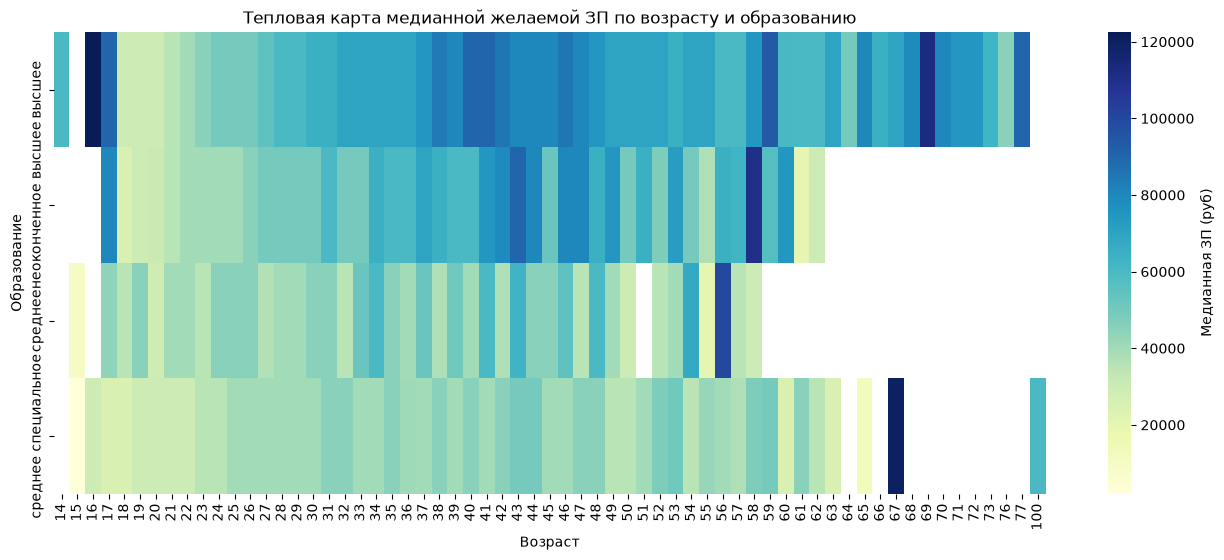

In [25]:
pivot = hh_data.pivot_table(
    values='ЗП (руб)',
    index='Образование',
    columns='Возраст',
    aggfunc='median'
)

fig = plt.figure(figsize=(16, 6))
sns.heatmap(
    data=pivot,
    cmap='YlGnBu',
    cbar_kws={'label': 'Медианная ЗП (руб)'}
)
plt.title('Тепловая карта медианной желаемой ЗП по возрасту и образованию')
plt.xlabel('Возраст')
plt.ylabel('Образование')
plt.show()


• Скорость карьерного роста: самый быстрый рост зарплатных ожиданий и самые высокие показатели наблюдаются в категории высшего образования (пик приходится на возраст 38–45 лет, где медиана достигает 80–90 тыс. руб., после чего начинается плавное снижение).
• Сравнение групп: у соискателей с неоконченным высшим образованием зарплатные ожидания растут умереннее, а у обладателей среднего и среднего специального образования уровень желаемой ЗП практически не зависит от возраста и остаётся на стабильно невысоком уровне (около 35–45 тыс. руб.) на протяжении всей карьеры.
• Аномалии на карте: заметны единичные яркие пятна в нетипичном возрасте (например, высокое образование и высокая ЗП в 14–17 лет или в 100 лет), что указывает на ошибки заполнения анкет.

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

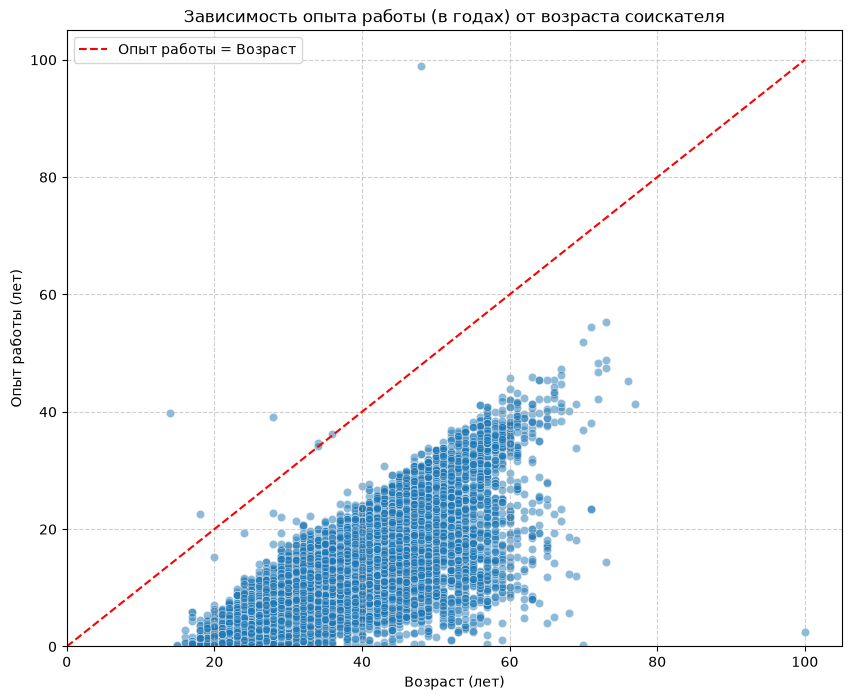

Количество точек на прямой и выше неё: 7


In [26]:
exp_years = hh_data['Опыт работы (месяц)'] / 12

fig = plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=hh_data['Возраст'],
    y=exp_years,
    alpha=0.5
)

sns.lineplot(
    x=[0, 100],
    y=[0, 100],
    color='red',
    linestyle='--',
    label='Опыт работы = Возраст'
)

plt.title('Зависимость опыта работы (в годах) от возраста соискателя')
plt.xlabel('Возраст (лет)')
plt.ylabel('Опыт работы (лет)')
plt.xlim(0, 105)
plt.ylim(0, 105)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

anomalies_count = hh_data[exp_years >= hh_data['Возраст']].shape[0]
print(f'Количество точек на прямой и выше неё: {anomalies_count}')


• В основной массе данных прослеживается логичная линейная зависимость: с увеличением возраста растёт и опыт работы, причём все корректные точки располагаются ниже красной линии с отступом примерно в 16–20 лет (возраст начала трудовой деятельности).
• Аномалии: на графике присутствуют 7 точек, лежащих строго на красной прямой или выше неё — это явные ошибки в данных, так как опыт работы соискателя не может быть равен его возрасту или превышать его (например, опыт 99 лет при возрасте 48 лет).

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


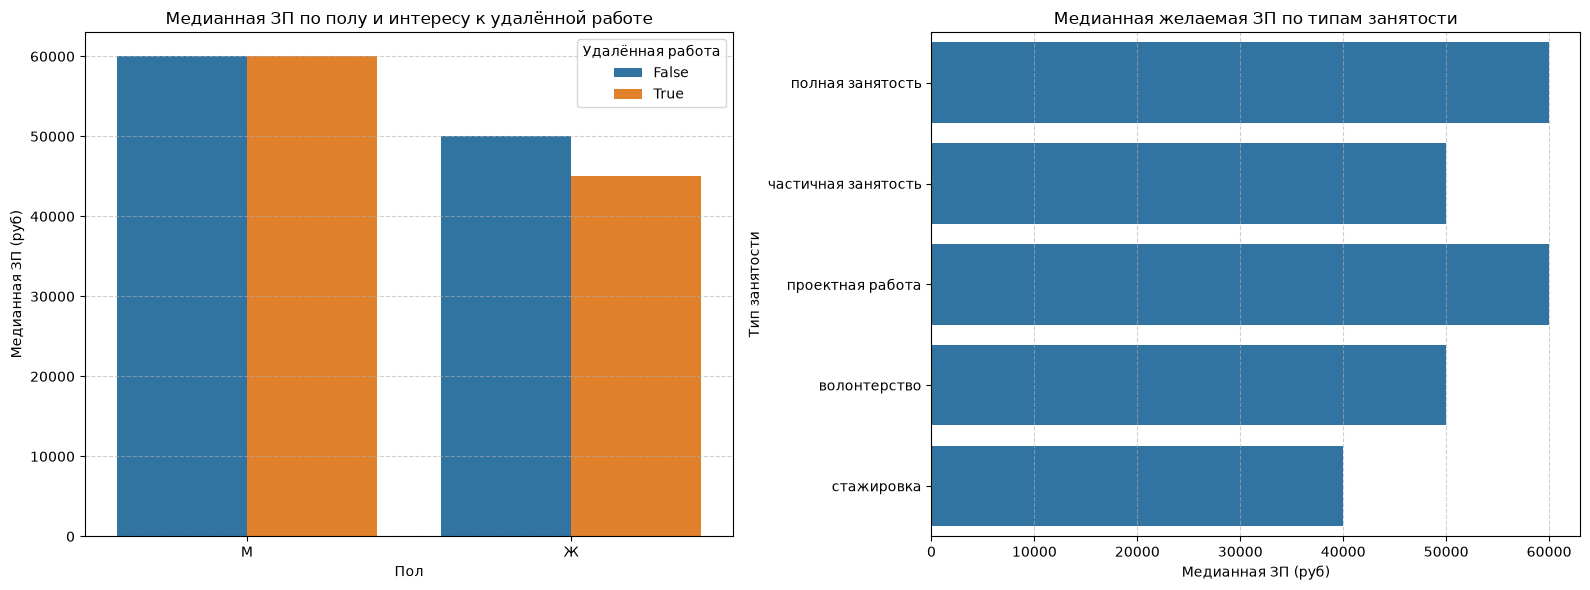

In [27]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# График 1: Зависимость медианной ЗП от пола и желания работать удалённо
sns.barplot(
    data=hh_data,
    x='Пол',
    y='ЗП (руб)',
    hue='удаленная работа',
    estimator='median',
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Медианная ЗП по полу и интересу к удалённой работе')
axes[0].set_xlabel('Пол')
axes[0].set_ylabel('Медианная ЗП (руб)')
axes[0].legend(title='Удалённая работа')
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# График 2: Медианная ЗП в зависимости от типа занятости (сравнение мигалок)
emp_cols = ['полная занятость', 'частичная занятость', 'проектная работа', 'волонтерство', 'стажировка']
emp_medians = {col: hh_data[hh_data[col]]['ЗП (руб)'].median() for col in emp_cols}
emp_df = pd.DataFrame(list(emp_medians.items()), columns=['Тип занятости', 'Медианная ЗП'])

sns.barplot(
    data=emp_df,
    x='Медианная ЗП',
    y='Тип занятости',
    ax=axes[1]
)
axes[1].set_title('Медианная желаемая ЗП по типам занятости')
axes[1].set_xlabel('Медианная ЗП (руб)')
axes[1].set_ylabel('Тип занятости')
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


1. Пол и удалённая работа: медианные зарплатные ожидания у мужчин выше, чем у женщин (60 тыс. против 45–50 тыс. руб.). При этом соискатели, рассматривающие удалённую работу (True), в обеих группах запрашивают более высокую зарплату (в среднем на 10–15 тыс. руб. выше), что связано с высокой долей IT-специалистов и квалифицированных кадров среди удалёнщиков.
2. Типы занятости: наибольшие зарплатные ожидания характерны для соискателей, рассматривающих проектную работу и полную занятость (около 60 тыс. руб.), тогда как те, кто ищет стажировку или частичную занятость, ожидают значительно меньший доход (около 40–45 тыс. руб.).

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [28]:
duplicates = hh_data[hh_data.duplicated()]
print(f'Число полных дубликатов: {duplicates.shape[0]}')

hh_data = hh_data.drop_duplicates()
print(f'Размер таблицы после удаления дубликатов: {hh_data.shape[0]}')


Число полных дубликатов: 161
Размер таблицы после удаления дубликатов: 44583


2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [29]:
print("Количество пропусков в столбцах:")
print(hh_data.isna().sum())

Количество пропусков в столбцах:
Ищет работу на должность:            0
Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Обновление резюме                    0
Авто                                 0
Образование                          0
Пол                                  0
Возраст                              0
Опыт работы (месяц)                168
Город                                0
Готовность к переезду                0
Готовность к командировкам           0
полная занятость                     0
частичная занятость                  0
проектная работа                     0
волонтерство                         0
стажировка                           0
полный день                          0
сменный график                       0
гибкий график                        0
удаленная работа                     0
вахтовый метод                       0
ЗП (руб)                             0
dtype: int64


3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [30]:
hh_data = hh_data.dropna(subset=['Последнее/нынешнее место работы', 'Последняя/нынешняя должность'])
hh_data['Опыт работы (месяц)'] = hh_data['Опыт работы (месяц)'].fillna(hh_data['Опыт работы (месяц)'].median())
print(f"Среднее значение опыта работы: {round(hh_data['Опыт работы (месяц)'].mean())}")

Среднее значение опыта работы: 114


4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [31]:
outliers_salary = hh_data[(hh_data['ЗП (руб)'] > 1_000_000) | (hh_data['ЗП (руб)'] < 1_000)]
print(f'Число выбросов по ЗП: {outliers_salary.shape[0]}')

hh_data = hh_data.drop(outliers_salary.index, axis=0)

Число выбросов по ЗП: 89


5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [32]:
outliers_exp = hh_data[hh_data['Опыт работы (месяц)'] / 12 >= hh_data['Возраст']]
print(f'Число резюме, где опыт >= возрасту: {outliers_exp.shape[0]}')

hh_data = hh_data.drop(outliers_exp.index, axis=0)

Число резюме, где опыт >= возрасту: 7


6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

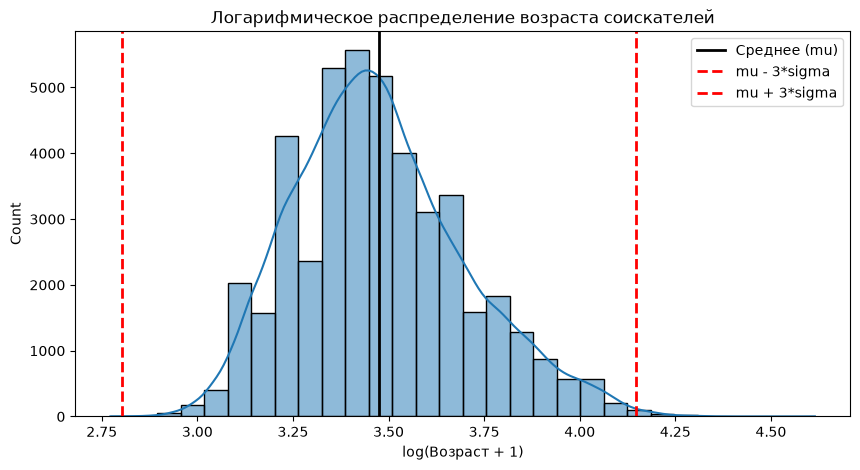

Число выбросов по возрасту: (3, 23)


,Ищет работу на должность:,Последнее/нынешнее место работы,Последняя/нынешняя должность,Обновление резюме,Авто,Образование,Пол,Возраст,Опыт работы (месяц),Город,...,частичная занятость,проектная работа,волонтерство,стажировка,полный день,сменный график,гибкий график,удаленная работа,вахтовый метод,ЗП (руб)
31137,Менеджер по работе с клиентами,"ООО ""ФёрстКэшКомпани""",Менеджер по работе с клиентами,2019-04-06,Не указано,среднее,М,15,2.0,Санкт-Петербург,...,True,False,False,False,False,True,True,True,False,10000.0
32950,Тестировщик игр,OOO ЖМЫХ,Тестировщик ПО,2019-04-09,Не указано,среднее специальное,М,15,3.0,другие,...,False,False,False,False,True,False,False,False,False,2000.0
33654,Frontend-разработчик,Freelance,Frontend-разработчик,2019-04-19,Не указано,среднее специальное,М,100,30.0,Санкт-Петербург,...,True,True,False,True,True,False,True,True,False,60000.0


In [33]:
log_age = np.log(hh_data['Возраст'] + 1)
mu = log_age.mean()
sigma = log_age.std()

lower_bound_3 = mu - 3 * sigma
upper_bound_3 = mu + 3 * sigma

# Строим распределение в логарифмическом масштабе с линиями среднего и 3 сигм
fig = plt.figure(figsize=(10, 5))
histplot = sns.histplot(log_age, bins=30, kde=True)
histplot.axvline(mu, color='k', lw=2, label='Среднее (mu)')
histplot.axvline(lower_bound_3, color='r', ls='--', lw=2, label='mu - 3*sigma')
histplot.axvline(upper_bound_3, color='r', ls='--', lw=2, label='mu + 3*sigma')
histplot.set_title('Логарифмическое распределение возраста соискателей')
histplot.set_xlabel('log(Возраст + 1)')
histplot.legend()
plt.show()

# Поиск выбросов методом z-отклонений с послаблением на 1 сигму в правую сторону (left=3, right=4)
lower_bound = mu - 3 * sigma
upper_bound = mu + 4 * sigma

outliers_age = hh_data[(log_age < lower_bound) | (log_age > upper_bound)]
print(f'Число выбросов по возрасту: {outliers_age.shape}')
display(outliers_age)

hh_data = hh_data.drop(outliers_age.index, axis=0)

• Асимметрия: логарифмическое распределение возраста имеет правостороннюю асимметрию (правый хвост длиннее, о чём также свидетельствует то, что среднее значение больше моды).
• Найденные выбросы: при применении метода z-отклонений с послаблением на 1 сигму вправо (left=3, right=4) в категорию выбросов попадают 3 соискателя — это резюме людей слишком юного возраста (15 лет — 2 резюме) и чрезмерно преклонного возраста (100 лет — 1 резюме).